
# IMDb Movie Review Sentiment Analysis

## Project Overview
This project develops a machine learning system to classify IMDb movie reviews as positive or negative.

## Dataset
- Dataset: IMDb movie reviews
- Total reviews: 50,000
- Positive reviews: 25,000
- Negative reviews: 25,000

## Methodology
1. Load and inspect the dataset.
2. Clean the review text.
3. Split the data into training and testing sets.
4. Convert text into TF-IDF features.
5. Train Logistic Regression and Multinomial Naive Bayes.
6. Evaluate and compare the models.
7. Visualize frequent words and test new reviews.

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

## Tools
Python, pandas, Matplotlib, and scikit-learn.

## Expected Deliverables
A runnable Google Colab notebook, model evaluation results,
visualizations, and a GitHub README.


In [26]:

print("Elevvo NLP Task 1: Sentiment Analysis")
print("My first machine learning project!")


Elevvo NLP Task 1: Sentiment Analysis
My first machine learning project!


In [2]:

!pip -q install datasets


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import html

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:

# Step 5A: Upload your Kaggle ZIP file to Colab

from google.colab import files

uploaded = files.upload()


Saving elevvo Imdb review dataset.zip to elevvo Imdb review dataset.zip


In [9]:

# Step 5B: Extract the ZIP and load the CSV

import zipfile
import io
import pandas as pd

zip_filename = next(iter(uploaded))

with zipfile.ZipFile(io.BytesIO(uploaded[zip_filename])) as zip_file:
    print("Files inside ZIP:", zip_file.namelist())

    with zip_file.open("IMDB.csv") as csv_file:
        df = pd.read_csv(csv_file)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Files inside ZIP: ['IMDB.csv']

Dataset loaded successfully!
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [10]:

# Step 6: Check data quality and sentiment labels

print("Column names:", df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment counts:")
print(df["sentiment"].value_counts())

print("\nUnique sentiment labels:")
print(df["sentiment"].unique())


Column names: ['review', 'sentiment']

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Unique sentiment labels:
['positive' 'negative']


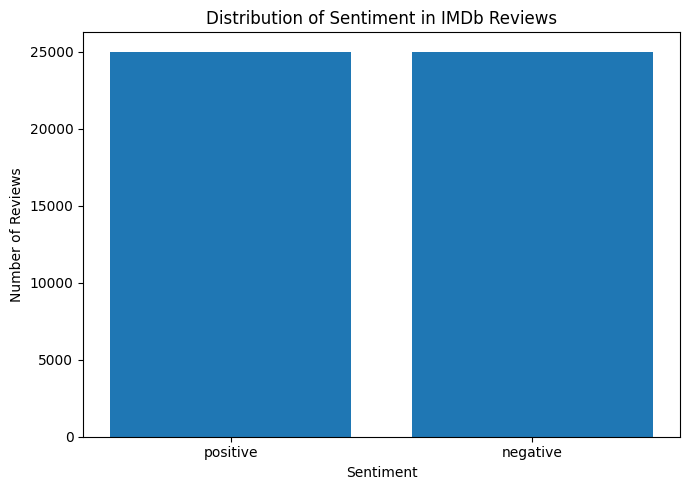

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [11]:

# Step 7: Visualise positive and negative reviews

sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title("Distribution of Sentiment in IMDb Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

print(sentiment_counts)


In [12]:

# Step 8: Convert sentiment labels into numbers

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

# Separate the review text and sentiment labels
X = df["review"]
y = df["label"]

print("Review examples:")
print(X.head(3))

print("\nNumeric labels:")
print(y.head(10))

print("\nLabel mapping: negative = 0, positive = 1")


Review examples:
0    One of the other reviewers has mentioned that ...
1    A wonderful little production. <br /><br />The...
2    I thought this was a wonderful way to spend ti...
Name: review, dtype: object

Numeric labels:
0    1
1    1
2    1
3    0
4    1
5    1
6    1
7    0
8    0
9    1
Name: label, dtype: int64

Label mapping: negative = 0, positive = 1


In [13]:

# Step 9: Define a text-cleaning function

import re
import html

def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# Apply the cleaning function
df["clean_review"] = df["review"].apply(clean_text)

print("Original review:")
print(df["review"].iloc[1][:400])

print("\nCleaned review:")
print(df["clean_review"].iloc[1][:400])


Original review:
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the referen

Cleaned review:
a wonderful little production. the filming technique is very unassuming- very old-time-bbc fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. the actors are extremely well chosen- michael sheen not only "has got all the polari" but he has all the voices down pat too! you can truly see the seamless editing guided by the references to williams' diary e


In [14]:

# Step 10: Split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Training reviews: 40000
Testing reviews: 10000

Training sentiment distribution:
label
1    20000
0    20000
Name: count, dtype: int64

Testing sentiment distribution:
label
0    5000
1    5000
Name: count, dtype: int64


In [15]:

# Step 11: Create TF-IDF features

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn vocabulary from training reviews only
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform test reviews using the same vocabulary
X_test_tfidf = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of vocabulary features:", len(vectorizer.vocabulary_))


Training feature matrix: (40000, 20000)
Testing feature matrix: (10000, 20000)
Number of vocabulary features: 20000


In [16]:

# Step 12: Train Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

# Predict sentiment for the test reviews
y_pred_logistic = logistic_model.predict(X_test_tfidf)

print("\nAccuracy:", round(
    accuracy_score(y_test, y_pred_logistic), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["Negative", "Positive"],
    digits=4
))


Logistic Regression training completed!

Accuracy: 0.908

Classification report:
              precision    recall  f1-score   support

    Negative     0.9125    0.9026    0.9075      5000
    Positive     0.9036    0.9134    0.9085      5000

    accuracy                         0.9080     10000
   macro avg     0.9080    0.9080    0.9080     10000
weighted avg     0.9080    0.9080    0.9080     10000



In [17]:

# Step 13: Train Multinomial Naive Bayes

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

naive_bayes_model = MultinomialNB()

naive_bayes_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")

# Predict on the same test set
y_pred_nb = naive_bayes_model.predict(X_test_tfidf)

print("\nAccuracy:", round(
    accuracy_score(y_test, y_pred_nb), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Negative", "Positive"],
    digits=4
))


Naive Bayes training completed!

Accuracy: 0.8783

Classification report:
              precision    recall  f1-score   support

    Negative     0.8853    0.8692    0.8772      5000
    Positive     0.8715    0.8874    0.8794      5000

    accuracy                         0.8783     10000
   macro avg     0.8784    0.8783    0.8783     10000
weighted avg     0.8784    0.8783    0.8783     10000



In [18]:

# Step 14: Compare Logistic Regression and Naive Bayes

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

model_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Multinomial Naive Bayes": y_pred_nb
}

for model_name, predictions in model_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9080,0.9036,0.9134,0.9085
1,Multinomial Naive Bayes,0.8783,0.8715,0.8874,0.8794


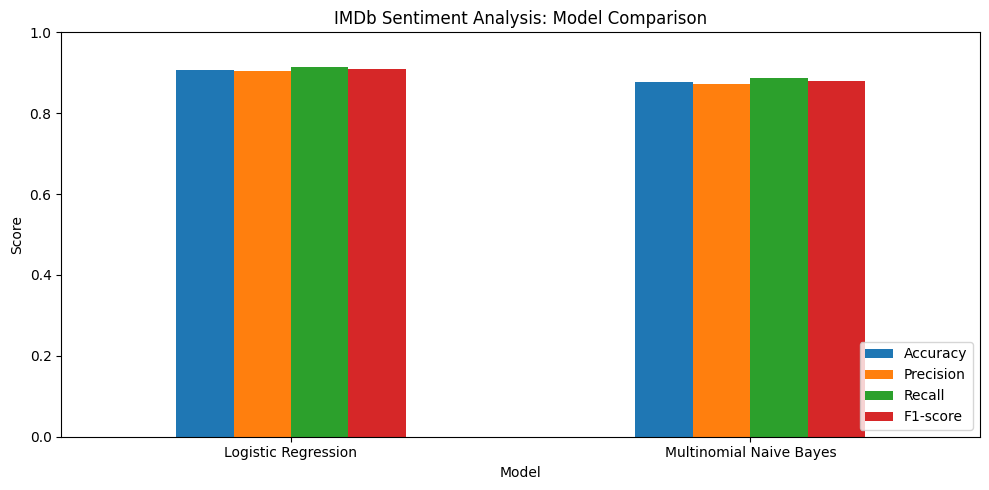

In [19]:

# Step 15: Visualise model performance

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("IMDb Sentiment Analysis: Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


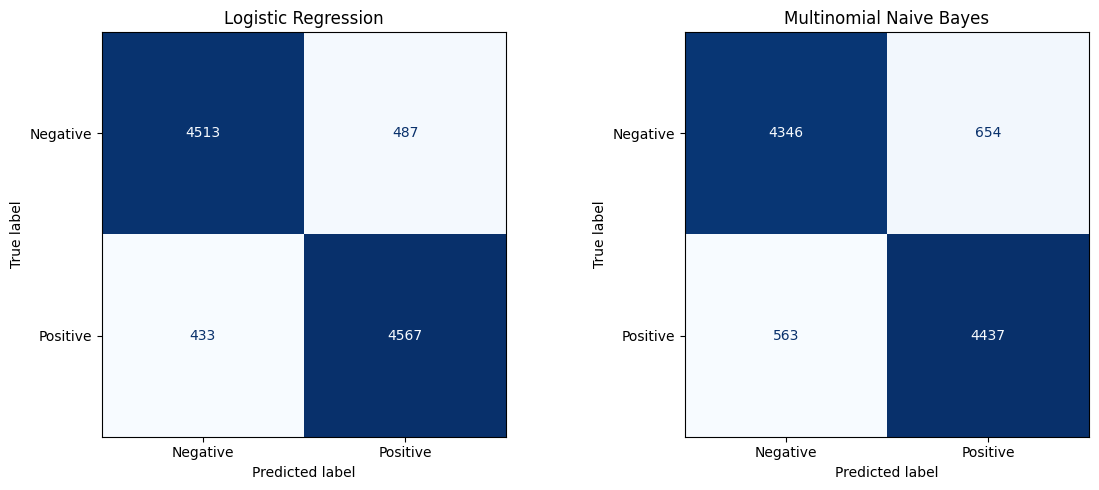

In [20]:

# Step 16: Plot confusion matrices for both models

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Multinomial Naive Bayes")

plt.tight_layout()
plt.show()


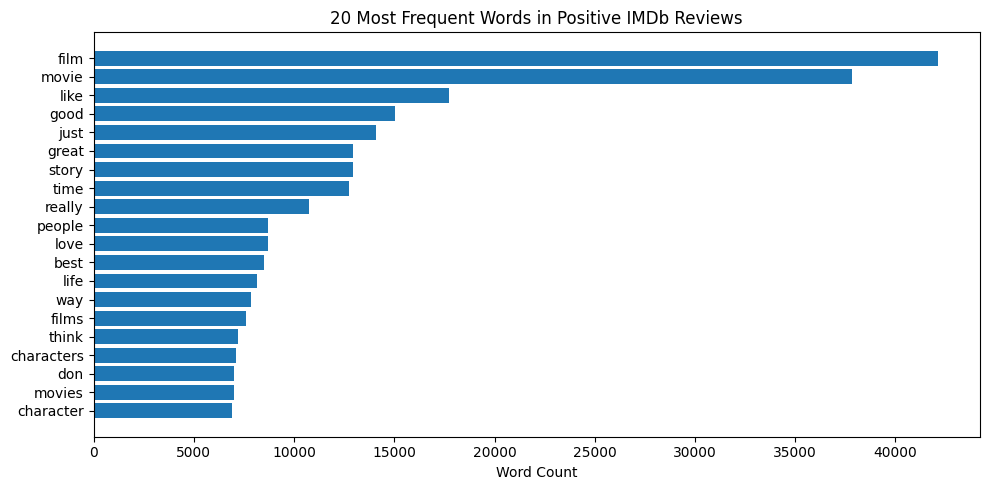

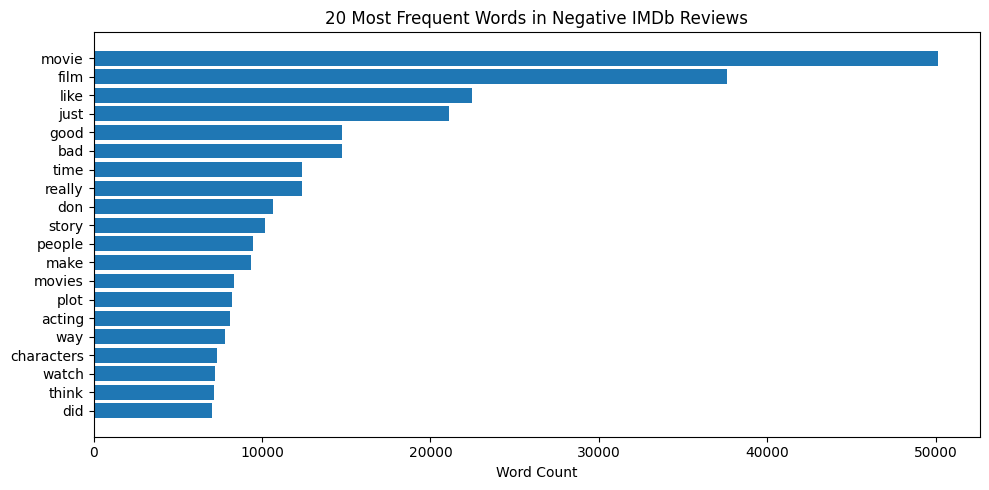

Top positive words:


,Word,Count
4,film,42110
12,movie,37854
10,like,17714
6,good,15025
8,just,14109
7,great,12964
16,story,12934
18,time,12752
15,really,10739
14,people,8719


Top negative words:


,Word,Count
10,movie,50116
5,film,37595
8,like,22458
7,just,21074
6,good,14728
1,bad,14726
17,time,12357
14,really,12355
4,don,10622
15,story,10185


In [21]:

from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import pandas as pd

# Separate reviews by sentiment
positive_reviews = df.loc[df["label"] == 1, "clean_review"]
negative_reviews = df.loc[df["label"] == 0, "clean_review"]

# Count words in positive reviews
word_vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)

positive_word_counts = word_vectorizer.fit_transform(positive_reviews)
positive_words = pd.DataFrame({
    "Word": word_vectorizer.get_feature_names_out(),
    "Count": positive_word_counts.sum(axis=0).A1
}).sort_values("Count", ascending=False)

# Count words in negative reviews
negative_word_counts = word_vectorizer.fit_transform(negative_reviews)
negative_words = pd.DataFrame({
    "Word": word_vectorizer.get_feature_names_out(),
    "Count": negative_word_counts.sum(axis=0).A1
}).sort_values("Count", ascending=False)

# Plot positive words
plt.figure(figsize=(10, 5))
plt.barh(positive_words["Word"], positive_words["Count"])
plt.gca().invert_yaxis()
plt.title("20 Most Frequent Words in Positive IMDb Reviews")
plt.xlabel("Word Count")
plt.tight_layout()
plt.show()

# Plot negative words
plt.figure(figsize=(10, 5))
plt.barh(negative_words["Word"], negative_words["Count"])
plt.gca().invert_yaxis()
plt.title("20 Most Frequent Words in Negative IMDb Reviews")
plt.xlabel("Word Count")
plt.tight_layout()
plt.show()

print("Top positive words:")
display(positive_words.head(10))

print("Top negative words:")
display(negative_words.head(10))


In [22]:

# Write your own sample reviews
sample_reviews = [
    "This movie was fantastic and the acting was amazing.",
    "This film was terrible, boring, and a complete waste of time.",
    "I did not enjoy this movie at all.",
    "The story was interesting and the performances were excellent."
]

# Apply the same cleaning function
clean_samples = [clean_text(review) for review in sample_reviews]

# Convert the reviews using the already-trained TF-IDF vectorizer
sample_tfidf = vectorizer.transform(clean_samples)

# Predict sentiment using Logistic Regression
sample_predictions = logistic_model.predict(sample_tfidf)
sample_probabilities = logistic_model.predict_proba(sample_tfidf)[:, 1]

# Display the predictions
for review, prediction, probability in zip(
    sample_reviews, sample_predictions, sample_probabilities
):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print(f"Review: {review}")
    print(f"Predicted sentiment: {sentiment}")
    print(f"Estimated positive probability: {probability:.2%}")
    print("-" * 60)


Review: This movie was fantastic and the acting was amazing.
Predicted sentiment: Positive
Estimated positive probability: 91.87%
------------------------------------------------------------
Review: This film was terrible, boring, and a complete waste of time.
Predicted sentiment: Negative
Estimated positive probability: 0.03%
------------------------------------------------------------
Review: I did not enjoy this movie at all.
Predicted sentiment: Negative
Estimated positive probability: 24.84%
------------------------------------------------------------
Review: The story was interesting and the performances were excellent.
Predicted sentiment: Positive
Estimated positive probability: 88.19%
------------------------------------------------------------


In [23]:

results_df.to_csv("model_comparison_results.csv", index=False)
print("Model comparison results saved successfully.")


Model comparison results saved successfully.


In [24]:

from google.colab import files
files.download("model_comparison_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>